# Análise exploratória — Microdados do ENEM 2025

Caderno de **exploração preliminar, prototipação e validação** do projeto
*Desigualdades no ENEM 2025: rede de ensino, território e perfil socioeconômico*.

| | |
|---|---|
| **Autor** | Victor Hugo Nespoli |
| **Instituição** | Centro Universitário La Salle do Rio de Janeiro (UNILASALLE-RJ) — Bacharelado em Sistemas de Informação |
| **Disciplina** | Linguagem de Programação (Análise e Visualização de Dados com Python) — 6º Período |
| **Semestre** | 2026/2 |
| **Fonte** | INEP, *Microdados do Enem 2025* |

O pipeline definitivo está em `src/etl.py`, e as figuras do artigo, em
`src/visualizacao.py`. Este caderno parte dos dados já processados
(`python -m src.etl`) e documenta as verificações que sustentam as decisões
metodológicas.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
from src.etl import DIR_PROCESSED, d_de_cohen, resumo_descritivo

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
res = pd.read_parquet(DIR_PROCESSED / "resultados_2025.parquet")
part = pd.read_parquet(DIR_PROCESSED / "participantes_2025.parquet")
mun = pd.read_csv(DIR_PROCESSED / "municipios_2025.csv.gz")
print(f"Resultados: {res.shape} | Participantes: {part.shape} | Municípios: {mun.shape}")

Resultados: (4810772, 31) | Participantes: (4810772, 20) | Municípios: (1805, 24)


## 1. Integridade e consistência

As bases não têm chave comum. Por isso, verificamos se os totais batem e se a
agregação por município de prova é consistente (razão de inscritos = 1).

In [2]:
assert len(res) == len(part), "As bases deveriam ter o mesmo número de inscritos"
print("Inscritos (ambas as bases):", f"{len(res):,}".replace(",", "."))
print("Razão de inscritos por município: min =", mun["RAZAO_INSCRITOS"].min(),
      "| max =", mun["RAZAO_INSCRITOS"].max())
res.memory_usage(deep=True).sum() / 1e6

Inscritos (ambas as bases): 4.810.772
Razão de inscritos por município: min = 1.0 | max = 1.0


np.float64(356.031999)

## 2. Valores ausentes

In [3]:
ausentes = res.isna().mean().sort_values(ascending=False)
ausentes[ausentes > 0].to_frame("proporção ausente")

,proporção ausente
SG_UF_ESC,0.639
NO_REDE,0.639
NO_LOCALIZACAO,0.639
NO_REDE_AGRUPADA,0.639
NU_MEDIA_GERAL,0.326
NU_MEDIA_OBJETIVAS,0.326
NU_NOTA_MT,0.322
NU_NOTA_CN,0.322
NU_NOTA_COMP3,0.281
NU_NOTA_COMP2,0.281


A ausência das notas coincide com a falta ou a eliminação, como confirma o
cruzamento abaixo. A ausência da rede (`NO_REDE`) corresponde aos inscritos sem
escola vinculada no Censo Escolar 2025 (egressos e treineiros). Por isso,
**nenhum valor foi imputado**.

In [4]:
pd.crosstab(res["TP_PRESENCA_MT"], res["NU_NOTA_MT"].isna(),
            rownames=["presença MT"], colnames=["nota MT ausente"])

nota MT ausente,False,True
presença MT,,
0,0,1548487
1,3260336,0
2,0,1949


## 3. Distribuição da média geral e valores atípicos

In [5]:
validos = res[res["IN_VALIDO"]]
pd.Series(resumo_descritivo(validos["NU_MEDIA_GERAL"]), name="média geral").to_frame()

,média geral
n,"3,244,348.000"
media,531.723
dp,93.533
cv,0.176
min,0.000
p10,417.440
q1,467.420
mediana,527.300
q3,594.420
p90,657.060


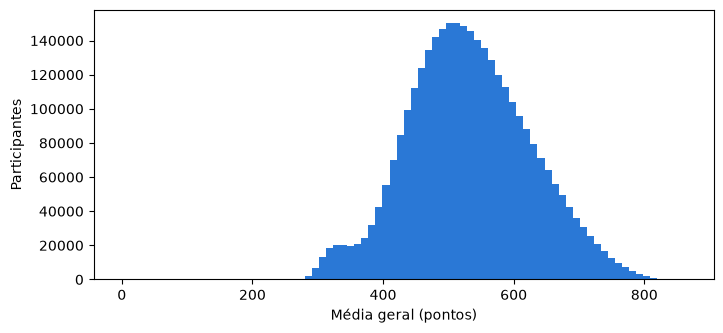

In [6]:
ax = validos["NU_MEDIA_GERAL"].plot.hist(bins=80, figsize=(8, 3.5), color="#2a78d6")
ax.set_xlabel("Média geral (pontos)"); ax.set_ylabel("Participantes");

A segunda concentração em torno de 330–340 pontos corresponde às redações
com nota zero (status diferente de "sem problemas"):

In [7]:
validos.groupby(validos["NU_NOTA_REDACAO"] == 0)["NU_MEDIA_GERAL"].describe()

,count,mean,std,min,25%,50%,75%,max
NU_NOTA_REDACAO,,,,,,,,
False,"3,073,011.000",541.397,85.674,56.000,477.280,533.560,598.760,862.960
True,"171,337.000",358.219,47.203,0.000,324.880,349.300,383.620,621.620


## 4. RQ1 — Rede e localização (protótipo)

In [8]:
com_rede = validos[validos["NO_REDE"].notna()]
com_rede.groupby("NO_REDE", observed=True)["NU_MEDIA_GERAL"].agg(["size", "mean", "median", "std"])

,size,mean,median,std
NO_REDE,,,,
Federal,68463,583.520,587.420,81.505
Estadual,961328,497.133,496.920,83.012
Municipal,6602,540.017,540.470,77.828
Privada,252092,610.458,615.640,83.657


In [9]:
print("d (Privada × Estadual):", round(d_de_cohen(
    com_rede.loc[com_rede.NO_REDE == "Privada", "NU_MEDIA_GERAL"],
    com_rede.loc[com_rede.NO_REDE == "Estadual", "NU_MEDIA_GERAL"]), 3))
com_rede.groupby("NO_LOCALIZACAO", observed=True)["NU_MEDIA_GERAL"].agg(["size", "mean", "median"])

d (Privada × Estadual): 1.363


,size,mean,median
NO_LOCALIZACAO,,,
Urbana,1225900,526.199,522.960
Rural,62585,483.294,479.700


## 5. RQ2 — Correlações municipais (protótipo)

In [10]:
m = mun[mun["N_VALIDOS"] >= 100]
print(len(m), "municípios;", f"{m['N_VALIDOS'].sum() / mun['N_VALIDOS'].sum():.2%}", "dos válidos")
cols = ["RENDA_PC_MEDIANA", "PCT_BAIXA_RENDA", "PCT_MAE_SEM_EM", "PCT_SEM_INTERNET",
        "PCT_SEM_COMPUTADOR", "PCT_ESCOLA_PUBLICA", "PCT_PPI", "PCT_TREINEIROS"]
m[cols + ["MEDIA_GERAL", "TX_ABSTENCAO_TOTAL"]].corr("spearman")[["MEDIA_GERAL", "TX_ABSTENCAO_TOTAL"]].loc[cols]

1787 municípios; 99.97% dos válidos


,MEDIA_GERAL,TX_ABSTENCAO_TOTAL
RENDA_PC_MEDIANA,0.857,0.123
PCT_BAIXA_RENDA,-0.858,-0.139
PCT_MAE_SEM_EM,-0.683,-0.169
PCT_SEM_INTERNET,-0.853,0.002
PCT_SEM_COMPUTADOR,-0.889,-0.107
PCT_ESCOLA_PUBLICA,-0.766,-0.003
PCT_PPI,-0.838,0.092
PCT_TREINEIROS,-0.030,-0.494


## 6. RQ3 — Abstenção (protótipo)

In [11]:
res[["IN_FALTOU_DIA1", "IN_FALTOU_DIA2", "IN_AUSENTE_TOTAL", "IN_ELIMINADO"]].mean().to_frame("proporção")

,proporção
IN_FALTOU_DIA1,0.280
IN_FALTOU_DIA2,0.322
IN_AUSENTE_TOTAL,0.277
IN_ELIMINADO,0.001


In [12]:
(res.groupby(res["NO_REDE"].astype("string").fillna("Sem escola vinculada"))["IN_AUSENTE_TOTAL"]
   .mean().sort_values().to_frame("abstenção"))

,abstenção
NO_REDE,
Privada,0.055
Federal,0.058
Municipal,0.226
Estadual,0.260
Sem escola vinculada,0.310


## 7. Perfil socioeconômico nacional dos inscritos

In [13]:
perfil = part[["IN_BAIXA_RENDA", "IN_MAE_SEM_EM", "IN_SEM_INTERNET", "IN_SEM_COMPUTADOR",
               "IN_ESCOLA_PUBLICA", "IN_PPI", "IN_TREINEIRO", "IN_CONCLUINTE_2025"]].astype(float).mean()
print("Renda per capita mediana estimada: R$", round(part["NU_RENDA_PC"].median(), 2))
perfil.to_frame("proporção")

Renda per capita mediana estimada: R$ 474.38


,proporção
IN_BAIXA_RENDA,0.648
IN_MAE_SEM_EM,0.382
IN_SEM_INTERNET,0.117
IN_SEM_COMPUTADOR,0.521
IN_ESCOLA_PUBLICA,0.771
IN_PPI,0.586
IN_TREINEIRO,0.205
IN_CONCLUINTE_2025,0.377


## Conclusões da exploração

- As duas bases são consistentes em contagem total e por município, o que
  valida a integração ecológica.
- Nota ausente significa falta ou eliminação, e não erro de coleta. Sem imputação.
- Os resultados preliminares de RQ1–RQ3 foram consolidados em
  `src/visualizacao.py` e discutidos no artigo (`docs/index.html`).